# Human players: fingerprints of central and peripheral players

The human version of the model characterisation notebook (`models/competitive/model_characterisation_demo260723.ipynb`). Players are grouped by where they wait when a trial starts, then compared on the same behavioural metrics as the models.

**Groups.** Within each session, players are ranked by mean slice-onset centrality. The top 20% are **central** and the bottom 20% **peripheral** (40 of 200 players each). The middle 60% are left out of the comparisons. These cuts are provisional.

**Sessions.** First solo, social and second solo are grouped and compared separately, and never pooled. Social comes first. A player can be in a group in one session and not in another.

**Trials** follow `strategy_characterisation.ipynb`. The first solo loses its first 5 trials, and social and second solo keep every trial.

**How the metrics differ from the models** (definitions in `fingerprint_metrics.md`)
- The two social players are different people, so every metric is per player.
- `latency_to_reach_wall`, `frac_trials_over_5s`, `winner_path_len`, `path_ratio` and `p_high` use the player's **own wins** only. In social play the trial ends when either player reaches a wall, so a lost trial's time belongs to the opponent. Solo players win every trial.
- `p_high` counts High/Low trials only. Both walls of a forced trial pay the same, so a forced trial scores from its type.
- `win_rate` is new, and social only.
- `mean_score` and `score_rate` use every trial, with a lost trial scoring 0. `score_rate` is total score over total trial time (slice onset to trigger), as for the models.
- Trial score is 1.0 for High, 0.4 for Low and 0 for a loss, the agent scale. The change in the logged cumulative score is checked against it below.
- Wall visibility uses the human FoV (110.36 degrees) and the occlusion-aware method.
- **Social player 1's movement is reconstructed from the host's log** (see "Player 1 is logged through the network" above). Between-trial movement is measured on the 30 Hz network tick grid for every player, so the stillness cutoffs are per tick rather than per frame. Everything else stays on logged frames.
- The movement thresholds (0.05 units and 0.5 degrees per frame) were set for the agents. `proportion_resting` describes a no-input frame here, and there is no penalty break for humans.

**Plan**
1. Load the tables and check them.
2. The groups on the centrality axis.
3. Social fingerprints.
4. Solo fingerprints.
5. The two groups across sessions.

## Known problems (found 2026-09-17)

Checked against the raw pickles, with positions as logged. Problems 2 and 4 are now handled. The rest still affect the results below, so read them before the interpretation cells.

1. **`path_ratio` is inflated by trials with a tiny straight-line distance.** Each trial's ratio is averaged, and trials that start almost at the wall reach ratios up to 106. Total route over total straight-line distance roughly halves the peripheral excess. The social peripheral median falls from 1.26 to 1.13 and the central one from 1.08 to 1.07. The model pipeline averages the same way.
2. **Rotation and standing still differ between the two social players because of how they are logged.** Player 1 (the networked client) logs yaw in smaller, smoothed steps. Exact-zero yaw steps fall from 43% (player 0) to 10% (player 1). In social, player 1 shows less no-rotation time (0.41 against 0.55) and less standing still, but the same players do not differ in the second solo. **This is now fixed by reconstructing player 1's movement** (next cell). Perfectly still frames still do not come back, so stillness cutoffs must stay at or above 0.8 degrees per tick.

3. **The first trial of the second solo starts at the spawn point.** 98% of second-solo first trials start exactly at (0, 0), as do 14% of social first trials. That trial's centrality, visibility and route are not a choice.
4. **Visibility latencies assumed 50 Hz.** Clean files log at about 48.25 Hz, so latencies came out 3.6% short, and the sessions logged at 30 to 46 Hz were off by up to 65%. **This is now fixed by converting each frame index with the trial's own logged times** (`mc.window_times`). Latencies over 1 s grow by 3.6% and short ones shrink, as the event rows either side of slice onset sit about a millisecond apart rather than 20. `trial_s` now matches the outcome table's trial time to the microsecond on all 47,690 trials. Standing still is measured on the tick grid, so it was never affected.
5. **`frac_never_visible` partly measures trial length.** 37% of never-visible trials last under 0.3 s, mostly social losses the opponent ended at once. Dropping trials under 0.3 s takes social peripheral from 3.7% to 1.9%, and second-solo peripheral from 3.2% to 1.0%.
6. **Some metrics rest on few trials.** Late visibility latency uses a median of 5 to 15 trials for peripheral players, and as few as 1 to 3. One social peripheral player has 2 High/Low wins. HH19's 3-trial first solo is in the peripheral group.
7. **Partners are not independent.** 9 central and 10 peripheral social pairs fall wholly in one group, so 38 of the 80 group players come in pairs. Do not read the p values.
8. **Session 291 (experiment 72, player 1, second solo) looks faulty.** The player moves about 0.24 units every frame, even between trials. It sits in the middle group.

Also noted:
- Player 1 is more peripheral than player 0 in social (0.58 against 0.66) and in the second solo (0.52 against 0.66), but not in the first solo. This is behavioural, as both solos log the player as local.
- The ordering of eta² holds at 10%, 20% and 30% cuts.
- Social peripheral routes stay shorter without instant wins (16.3 against 19.9).

## Player 1 is logged through the network, and is recovered here

**The problem.** The social log is written on player 0's computer (the host). Player 0's position and yaw are logged as they happen, about 48 times a second. Player 1's arrive over the network, through Netcode's `ClientNetworkTransform` (version 1.7.1, `Interpolate` on):

1. Player 1's computer sends its transform 30 times a second (`TickRate: 30`).
2. The host shows each update one tick (33 ms) late.
3. Frames between updates are filled in by straight-line interpolation.
4. The result is smoothed again with `lerp(current, target, deltaTime / 0.1)` (`BufferedLinearInterpolator.cs:220`).

Step 4 makes every stop ease in over several frames instead of stopping dead. As logged, player 1 shows less standing still than player 0 (no-rotation 0.41 against 0.55, p < 0.001; resting 0.21 against 0.29, p = 0.004), while the same players differ on neither in their solo sessions. It also delays player 1's position and heading, which matters for wall visibility.

**What this notebook does.** Player 1's real movement is reconstructed. All four steps above are in the engine source, so the path is known exactly, and it is linear: `logged = smoothing x interpolation x samples`. `network_compensation.py` solves for the 30 Hz samples that best reproduce the logged trace, with a penalty on jitter so the answer cannot chase the millisecond of uncertainty in the frame timestamps. The write-up is `data_extraction/network_compensation/network_compensation.md`.

- **Movement between trials** (`prop_no_translational`, `prop_no_rotational`, `proportion_resting`, `iti_path_len`, `rot_total`, `iti_centrality`) is measured on the 30 Hz tick grid for **every** player, social and solo. Player 1 is recovered, everyone else is read from their own local trace at the same instants. The stillness cutoffs are the agent per-frame thresholds rescaled to a 33 ms step (0.8 degrees and 0.08 units per tick).
- **Wall visibility, head angle, routes and slice-onset position** stay on frames, with player 1's frames taken from the recovered trace. That removes the 33 ms delay and the heading error, which reached 38 degrees at the 95th percentile.
- **Trial outcomes** (winner, scores, times) come from log events and never touched the network path, so they are unchanged.

**How well it works.** Player 0's own trace gives a known answer: run it through the path, recover it, and compare. Stillness comes back within 0.003, total distance and rotation within 0.3%, positions within 0.0003 units. On the real data, player 0 and player 1 now agree on every movement measure (table below), where as logged they differed by a third.

**Limits.**
- 30 Hz is the ceiling. Movement between ticks was never sent, so it cannot be recovered, which is why every player is measured on that grid.
- Perfectly still frames do not come back. Cutoffs finer than about 0.4 degrees per tick still separate a recovered player from a locally logged one, so the cutoffs above are floors, not preferences.
- The Netcode settings are read from the current Unity project, and are not confirmed for the builds the experiments ran on.
- An earlier version of this notebook went the other way and simulated the network path onto player 0 (`hc.network_view`). That made the players comparable by degrading good data, and could not undo the delay. It is kept for comparison.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import analysis.human_characterisation as hc
import analysis.model_characterisation as mc
import plotting.plot_octagon as plot_octagon

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

RECOMPUTE = False                   # rebuild the cached fingerprint tables (loads both pickles, several GB each)
EXTREME_FRAC = hc.EXTREME_FRAC      # share of players in each group, per session

LABELS = hc.SESSION_LABELS
GROUPS = list(hc.GROUPS)
PALETTE = hc.STRAT_PALETTE

## 1. Load data

The onset table and the player table are the same as in `strategy_characterisation.ipynb`. The fingerprint tables are built once and cached. They hold one row per ITI (`iti`), per trial per player (`vis`, `outcome`) and per won trial (`win`).

In [2]:
# get the onset table and the player table (one row per player per session)
tables = hc.load_tables()
onset, _ = hc.fit_trial_split(tables['onset'])
players = hc.player_table(onset)
players['fixed'] = hc.fixed_cut_labels(players['frac_peripheral'])

# label the top and bottom share of each session
players = hc.extreme_groups(players, frac=EXTREME_FRAC)

# get the fingerprint tables and reduce them to one row per player per session
fp_tables = hc.load_fingerprint_tables(recompute=RECOMPUTE)
fingerprint = hc.build_player_fingerprint(players, fp_tables)

print({k: v.shape for k, v in fp_tables.items()})
pd.crosstab(fingerprint['session_type'], fingerprint['group']).loc[list(hc.SESSION_TYPES)]

human_onset_tables: loaded from cache


human_fingerprint_tables: loaded from cache
{'vis': (47690, 8), 'win': (34450, 7), 'outcome': (47690, 10), 'iti': (47281, 11)}


group,central,middle,peripheral
session_type,,,
solo1,40,120,40
social,40,120,40
solo2,40,120,40


### Checks

- **Score scale.** The score built from each outcome is compared with the change in the logged cumulative score, by year of the experiment. The human builds log High as 50 and Low as 20, so the logged change is divided by 50.
- **Trial types.** `p_high` uses High/Low trials only, so the table shows how many trials that leaves.
- **Coverage.** Every kept trial should have an outcome row and, in most cases, a visibility row.

In [3]:
experiments = hc.experiment_info(hc.session_files()[0])
out = fp_tables['outcome'].merge(experiments[['experiment', 'date']], on='experiment')
out['match'] = np.isclose(out['score'], out['score_logged'] / hc.LOGGED_HIGH_SCORE)

# compare the two scores by year, and show any logged values that differ
print('outcome score matches the logged score change')
display(out.groupby(out['date'].dt.year)['match'].agg(['mean', 'size']).round(4))
display(out.loc[~out['match'], ['trial_type', 'score', 'score_logged']].value_counts().head(10).rename('trials'))

# count trial types per session
display(pd.crosstab(out['session_type'], out['trial_type']))

# compare row counts with the onset table
coverage = pd.DataFrame(dict(onset=onset.groupby('session_type').size(),
                             outcome=fp_tables['outcome'].groupby('session_type').size(),
                             vis=fp_tables['vis'].groupby('session_type').size(),
                             won_trials=fp_tables['win'].groupby('session_type').size(),
                             itis=fp_tables['iti'].groupby('session_type').size()))
coverage.loc[list(hc.SESSION_TYPES)]

human_session_files: loaded from cache
outcome score matches the logged score change


,mean,size
date,,
2024,1.0000,6758
2025,1.0000,25105
2026,0.9998,15827


Series([], Name: trials, dtype: int64)

trial_type,ForcedHigh,ForcedLow,HighLow
session_type,,,
social,2714,2644,21122
solo1,1029,997,7907
solo2,1144,1125,9008


,onset,outcome,vis,won_trials,itis
session_type,,,,,
solo1,9933,9933,9933,9933,9933
social,26479,26480,26480,13240,26271
solo2,11277,11277,11277,11277,11077


**Interpretation**

- The outcome score matches the logged score change on every trial but 4, whose logged score is missing. The human builds pay 50 and 20, the same ratio as the agent scale.
- About 20% of trials are forced (ForcedHigh or ForcedLow). They are left out of `p_high`.
- Every kept trial has an outcome row and a visibility row. One social trial has no slice onset.
- Social and second solo each lose one ITI per player, the wait before the first trial. The first solo loses none, as a cut trial comes before its first kept trial.

### Player 0 against player 1 after the recovery

In social, the same metrics for the two players, paired within each experiment. With positions as logged, `prop_no_rotational` differed at p < 0.001 and `proportion_resting` at p = 0.004. After the recovery, no difference should remain beyond the seat difference in where players wait.

In [4]:
from scipy import stats

soc = fingerprint[fingerprint['session_type'] == 'social'].set_index(['experiment', 'player'])
rows = []
for m in ['prop_no_translational', 'prop_no_rotational', 'proportion_resting', 'iti_path_len', 'rot_total',
          'frac_visible_at_onset', 'all_latency_to_wall_visible', 'winner_path_len', 'onset_centrality']:
    a, b = soc[m].xs(0, level='player'), soc[m].xs(1, level='player')
    d = (a - b).dropna()
    rows.append(dict(metric=m, player_0=a.median(), player_1=b.median(), p_paired=stats.wilcoxon(d).pvalue))
pd.DataFrame(rows).set_index('metric').round(4)

,player_0,player_1,p_paired
metric,,,
prop_no_translational,0.6577,0.6271,0.2145
prop_no_rotational,0.5377,0.5264,0.6824
proportion_resting,0.2793,0.2808,0.5474
iti_path_len,12.3461,13.2459,0.1458
rot_total,322.7138,317.8911,0.8151
frac_visible_at_onset,0.7010,0.7033,0.0289
all_latency_to_wall_visible,0.1792,0.1605,0.0577
winner_path_len,19.2480,19.3121,0.9042
onset_centrality,0.6613,0.5800,0.0011


**Interpretation**

- After the recovery, player 0 and player 1 no longer differ on ITI movement, rotation or route length (p from 0.15 to 0.90). As logged, no-rotation was 0.55 against 0.41. It is now 0.538 against 0.526, and both sit at player 0's own local value, rather than both being dragged down to player 1's.
- Wall in view at onset still differs slightly (0.701 against 0.703, p = 0.03). Player 1 waits nearer the walls, which by itself puts a wall in view more often.
- Onset centrality differs (0.66 against 0.58). It comes from the logged onset table, and the same seat difference appears in the second solo, where both players are logged locally, so it is behaviour rather than logging.

## 2. The groups on the centrality axis

Each panel ranks one session's players by mean onset centrality. Bars are coloured by group and whiskers give the SD over trials. The lower row shows the same means as a histogram.

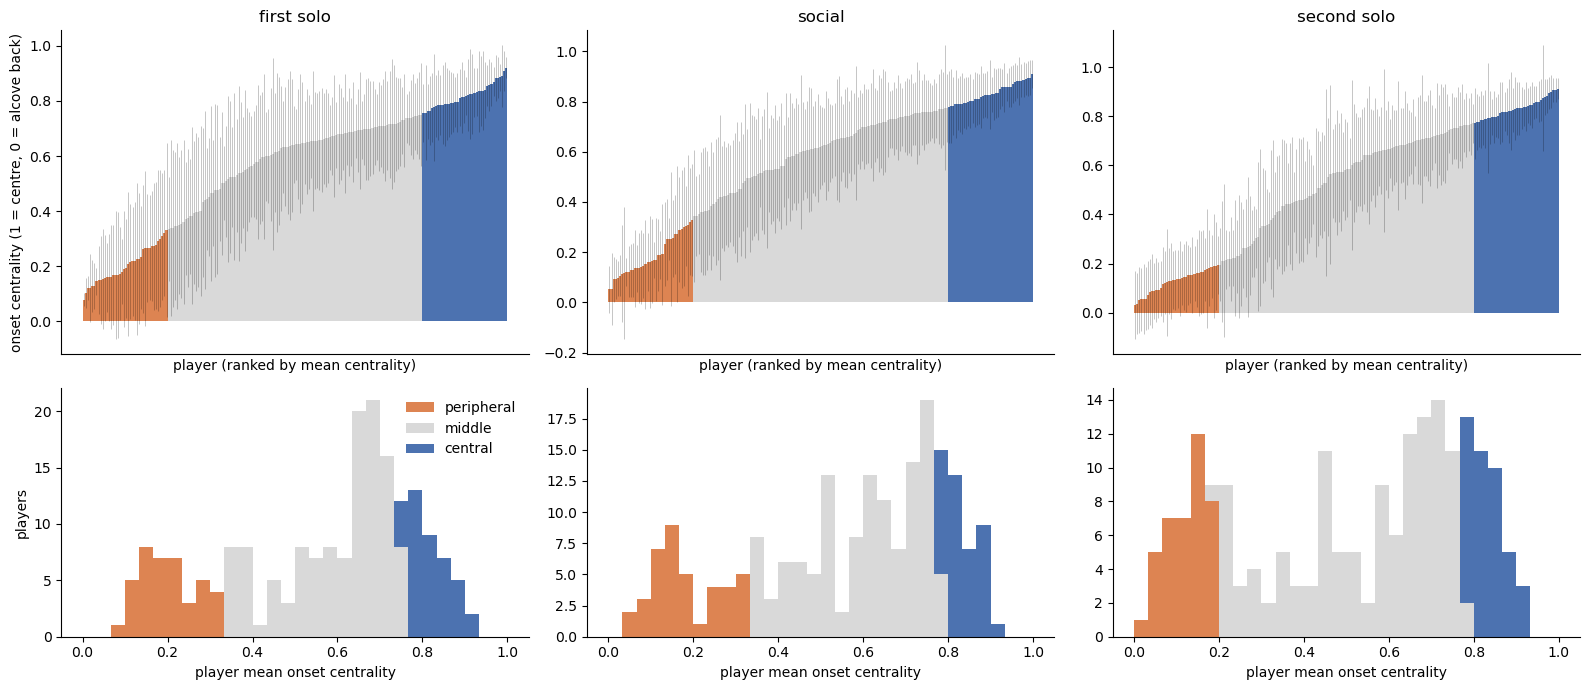

size    min  median    max
session_type group                                 
solo1        central       40  0.756   0.817  0.921
             peripheral    40  0.078   0.191  0.331
social       central       40  0.778   0.828  0.910
             peripheral    40  0.053   0.163  0.329
solo2        central       40  0.772   0.832  0.912
             peripheral    40  0.032   0.135  0.194

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), gridspec_kw=dict(height_ratios=[1.3, 1]))
for i, st in enumerate(hc.SESSION_TYPES):
    sub = players[players['session_type'] == st].sort_values('mean_centrality').reset_index(drop=True)
    colours = [PALETTE.get(g, '#D9D9D9') for g in sub['group']]

    # plot every player's mean, ranked
    ax = axes[0, i]
    ax.bar(sub.index, sub['mean_centrality'], yerr=sub['sd_centrality'], color=colours, width=1,
           error_kw=dict(lw=0.4, alpha=0.4))
    ax.set_title(LABELS[st])
    ax.set_xlabel('player (ranked by mean centrality)')
    ax.set_xticks([])

    # plot the histogram of means, stacked by group
    ax = axes[1, i]
    order = ['peripheral', 'middle', 'central']
    ax.hist([sub.loc[sub['group'] == g, 'mean_centrality'] for g in order], bins=np.linspace(0, 1, 31),
            stacked=True, color=[PALETTE.get(g, '#D9D9D9') for g in order], label=order)
    ax.set_xlabel('player mean onset centrality')

axes[0, 0].set_ylabel('onset centrality (1 = centre, 0 = alcove back)')
axes[1, 0].set_ylabel('players')
axes[1, 0].legend(frameon=False)
for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# show the centrality range each group covers
ranges = (players[players['group'].isin(GROUPS)]
          .groupby(['session_type', 'group'])['mean_centrality'].agg(['size', 'min', 'median', 'max']))
ranges.loc[list(hc.SESSION_TYPES)].round(3)

**Interpretation**

- The groups cover similar ranges in all three sessions. Central players sit at 0.76 to 0.92. Peripheral players sit at or below 0.33, and at or below 0.19 in the second solo.
- The second solo has a clear wall peak, so its peripheral group is tighter.

The fixed-cut labels from `strategy_characterisation.ipynb` against the 20% groups. The 20% groups sit inside the fixed-cut central and peripheral players, unless a session has fewer than 40 of them.

In [6]:
for st in hc.SESSION_TYPES:
    sub = players[players['session_type'] == st]
    print(LABELS[st])
    display(pd.crosstab(sub['group'], sub['fixed']))

first solo


fixed,central,mixed,peripheral
group,,,
central,40,0,0
middle,60,59,1
peripheral,0,8,32


social


fixed,central,mixed,peripheral
group,,,
central,40,0,0
middle,55,63,2
peripheral,0,6,34


second solo


fixed,central,mixed,peripheral
group,,,
central,40,0,0
middle,47,55,18
peripheral,0,0,40


**Interpretation**

- Every central-group player is a fixed-cut central player.
- Most peripheral-group players are fixed-cut peripheral. The first solo adds 8 mixed players and social adds 6.
- The second solo has 58 fixed-cut peripheral players, so 18 of them are left in the middle.

## 3. Social fingerprints

For each metric, eta² is the share of its spread between the two groups (1 = all between groups, 0 = all within). It is descriptive only. The groups are picked by onset centrality, so metrics that follow centrality separate by construction. Partners can also land in the same group, so players are not independent. Read the ordering, not the p values.

social: share of spread between the groups (eta²)


,metric,eta2_between_strategy,p_anova,central_mean,peripheral_mean
0,onset_centrality,0.966,0.000,0.834,0.185
1,iti_centrality,0.954,0.000,0.803,0.188
9,frac_visible_at_onset,0.664,0.000,0.671,0.839
7,winner_path_len,0.480,0.000,20.170,15.494
8,path_ratio,0.354,0.000,1.112,1.356
6,rot_total,0.306,0.000,503.199,226.548
15,p_high,0.266,0.000,0.778,0.655
4,proportion_resting,0.178,0.000,0.260,0.431
13,frac_never_visible,0.132,0.001,0.005,0.035
3,prop_no_rotational,0.131,0.001,0.503,0.617


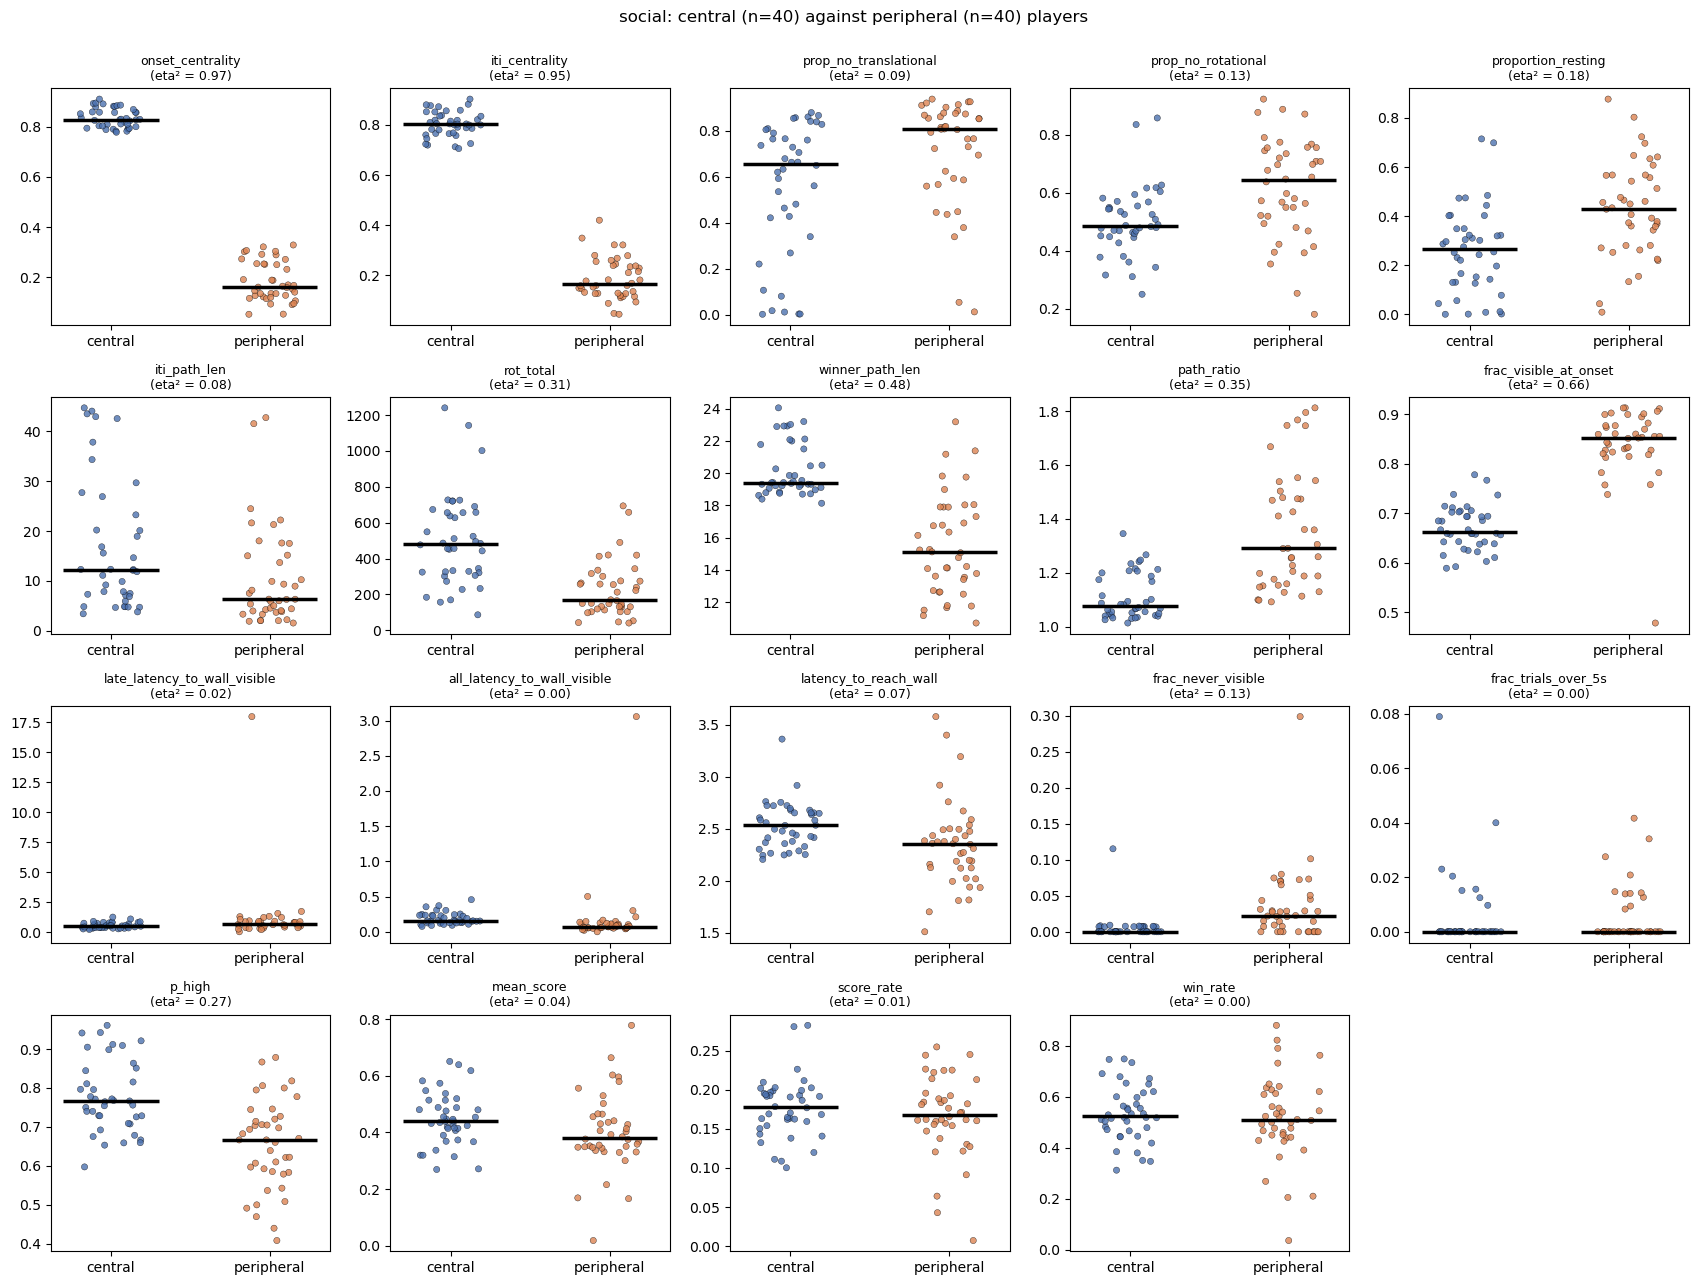

In [7]:
def plot_fingerprint(st):
    ''' Plot central against peripheral players on every fingerprint metric for one session.
        Takes a session type. Dots are players and bars are group medians. '''

    sub = fingerprint[(fingerprint['session_type'] == st) & fingerprint['group'].isin(GROUPS)]
    metrics = [m for m in hc.FP_METRICS if sub[m].notna().any()]
    eta = hc.group_variance(fingerprint, st, metrics).set_index('metric')['eta2_between_strategy']
    ncol = 5
    nrow = int(np.ceil(len(metrics) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(17, 3.2 * nrow))
    for ax, m in zip(axes.ravel(), metrics):
        sns.stripplot(data=sub, x='group', y=m, order=GROUPS, hue='group', palette=PALETTE, size=4.5,
                      jitter=0.2, alpha=0.8, edgecolor='black', linewidth=0.3, legend=False, ax=ax)
        # plot each group's median
        med = sub.groupby('group')[m].median()
        for i, g in enumerate(GROUPS):
            ax.hlines(med[g], i - 0.3, i + 0.3, color='black', lw=2.5, zorder=5)
        ax.set_title(f'{m}\n(eta² = {eta[m]:.2f})', fontsize=9)
        ax.set_xlabel('')
        ax.set_ylabel('')
    for ax in axes.ravel()[len(metrics):]:
        ax.axis('off')
    n = sub['group'].value_counts()
    plt.suptitle(f"{LABELS[st]}: central (n={n['central']}) against peripheral (n={n['peripheral']}) players",
                 y=1.0)
    plt.tight_layout()
    plt.show()


print('social: share of spread between the groups (eta²)')
display(hc.group_variance(fingerprint, 'social').round(3))
plot_fingerprint('social')

**Interpretation**

- Beyond centrality, the largest difference is the view at onset. Peripheral players have a trial wall in view on 84% of trials, against 68% for central players (eta² 0.65).
- Peripheral players take shorter routes on the trials they win (15.5 against 20.2). Their routes look less direct (path ratio 1.36 against 1.11), but part of that gap comes from how the ratio is averaged (problem 1).
- Peripheral players turn less during the ITI (227 against 503 degrees) and rest more (0.43 against 0.26 of ITI ticks, eta² 0.18).
- Peripheral players reach High less often on their wins (0.66 against 0.78).
- Win rate, mean score and score rate barely differ (eta² 0.04 or less). Neither group scores better.
- Latency to the wall is similar (2.3 against 2.5 s).
- One peripheral player has a late latency of 18 s, from few trials.

### Where each group waits at slice onset

Slice-onset positions of every trial of each group's players, on log counts.

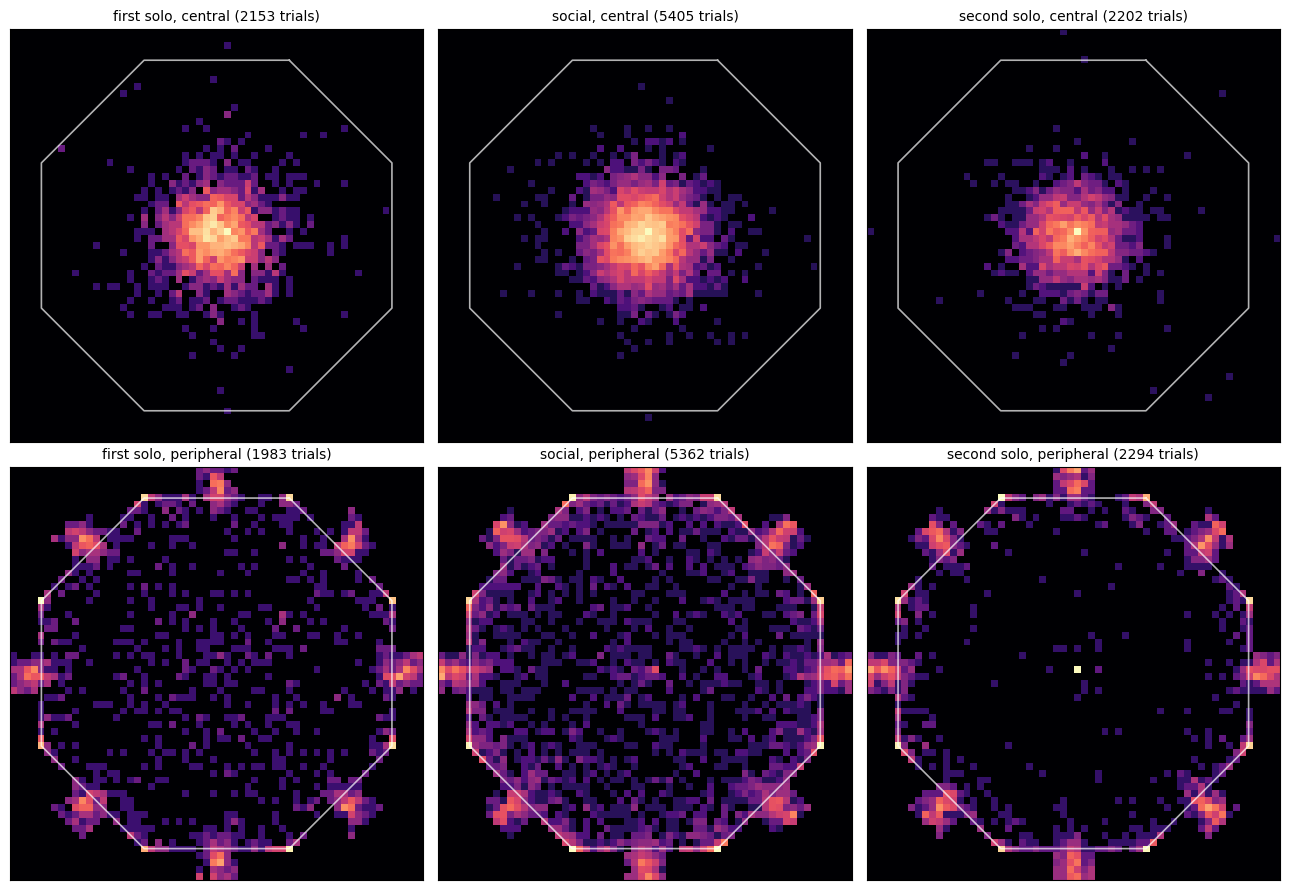

In [8]:
HIST_BINS = 60
R = mc.ARENA_RADIUS
hrange = [[-R, R], [-R, R]]
oct_x, oct_y = plot_octagon.calculate_coordinates(vertex=True)
keys = list(hc.KEYS)
onset_g = onset.merge(players[keys + ['group']], on=keys)

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for j, st in enumerate(hc.SESSION_TYPES):
    for i, g in enumerate(GROUPS):
        ax = axes[i, j]
        sub = onset_g[(onset_g['session_type'] == st) & (onset_g['group'] == g)]
        H, _, _ = np.histogram2d(sub['x'].to_numpy(float), sub['z'].to_numpy(float), bins=HIST_BINS, range=hrange)
        ax.imshow(np.log1p(H).T, origin='lower', extent=[-R, R, -R, R], cmap='magma', aspect='equal')
        ax.plot(oct_x, oct_y, color='white', lw=1.2, alpha=0.7)
        ax.set_title(f'{LABELS[st]}, {g} ({len(sub)} trials)', fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

**Interpretation**

- Central players wait in a disc around the centre.
- Peripheral players wait in the alcoves and on the octagon corners between them.
- Social peripheral trials spread further into the arena than solo ones, as the group includes players up to 0.33.

### When each group first sees a wall

Cumulative share of trials with a trial wall in view, from slice onset. Thin lines are players and bold lines the group mean. A trial that ends before a wall comes into view never counts as seen, so the curves plateau below 1. The lower panels give the share of trials still running.

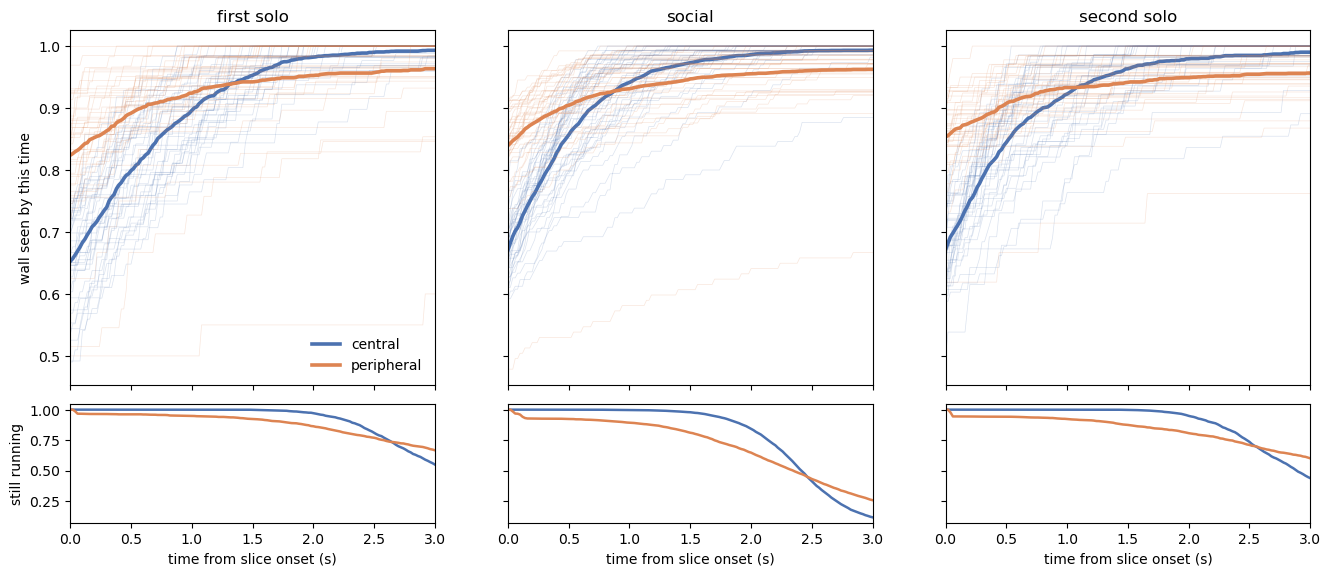

In [9]:
curve = hc.wall_visible_curve(fingerprint, fp_tables['vis'], max_s=3.0)

fig, axes = plt.subplots(2, 3, figsize=(16, 6.4), sharex=True, sharey='row',
                         gridspec_kw=dict(height_ratios=[3, 1], hspace=0.08))
for j, st in enumerate(hc.SESSION_TYPES):
    ax, axr = axes[0, j], axes[1, j]
    for g in GROUPS:
        sub = curve[(curve['session_type'] == st) & (curve['group'] == g)]
        # plot one thin line per player
        for _, p in sub.groupby(['experiment', 'player']):
            ax.plot(p['t'], p['p_visible'], color=PALETTE[g], lw=0.5, alpha=0.2)
        # plot the group mean over the top
        m = sub.groupby('t')[['p_visible', 'p_running']].mean()
        ax.plot(m.index, m['p_visible'], color=PALETTE[g], lw=2.6, label=g)
        axr.plot(m.index, m['p_running'], color=PALETTE[g], lw=1.8)
    ax.set_title(LABELS[st])
    axr.set_xlabel('time from slice onset (s)')
axes[0, 0].set_ylabel('wall seen by this time')
axes[1, 0].set_ylabel('still running')
axes[0, 0].legend(frameon=False, loc='lower right')
axes[1, 0].set_xlim(0, 3)
plt.show()

**Interpretation**

- Peripheral players start with a wall in view more often. Central players catch up by 0.9 s (social), 1.3 s (first solo) and 1.1 s (second solo), and end higher.
- Peripheral curves level off lower, as 2 to 4% of their trials end with no trial wall seen.
- Some peripheral wins end almost at once. Of their won trials, 7.3% (social), 3.3% (first solo) and 5.4% (second solo) end within 0.1 s of slice onset, against 0.1% or less for central players. That is the drop at 0 s in the lower panels.

## 4. Solo fingerprints

The same comparison in the first and second solo. The groups are ranked again within each solo, so they are not the social groups.

first solo: share of spread between the groups (eta²)


,metric,eta2_between_strategy,p_anova,central_mean,peripheral_mean
0,onset_centrality,0.969,0.000,0.821,0.203
1,iti_centrality,0.941,0.000,0.792,0.222
9,frac_visible_at_onset,0.479,0.000,0.653,0.824
6,rot_total,0.262,0.000,353.295,181.267
13,frac_never_visible,0.161,0.000,0.000,0.020
7,winner_path_len,0.141,0.001,21.710,27.675
8,path_ratio,0.137,0.001,1.164,1.501
3,prop_no_rotational,0.117,0.002,0.567,0.676
16,mean_score,0.077,0.013,0.914,0.871
12,latency_to_reach_wall,0.077,0.013,3.324,4.366


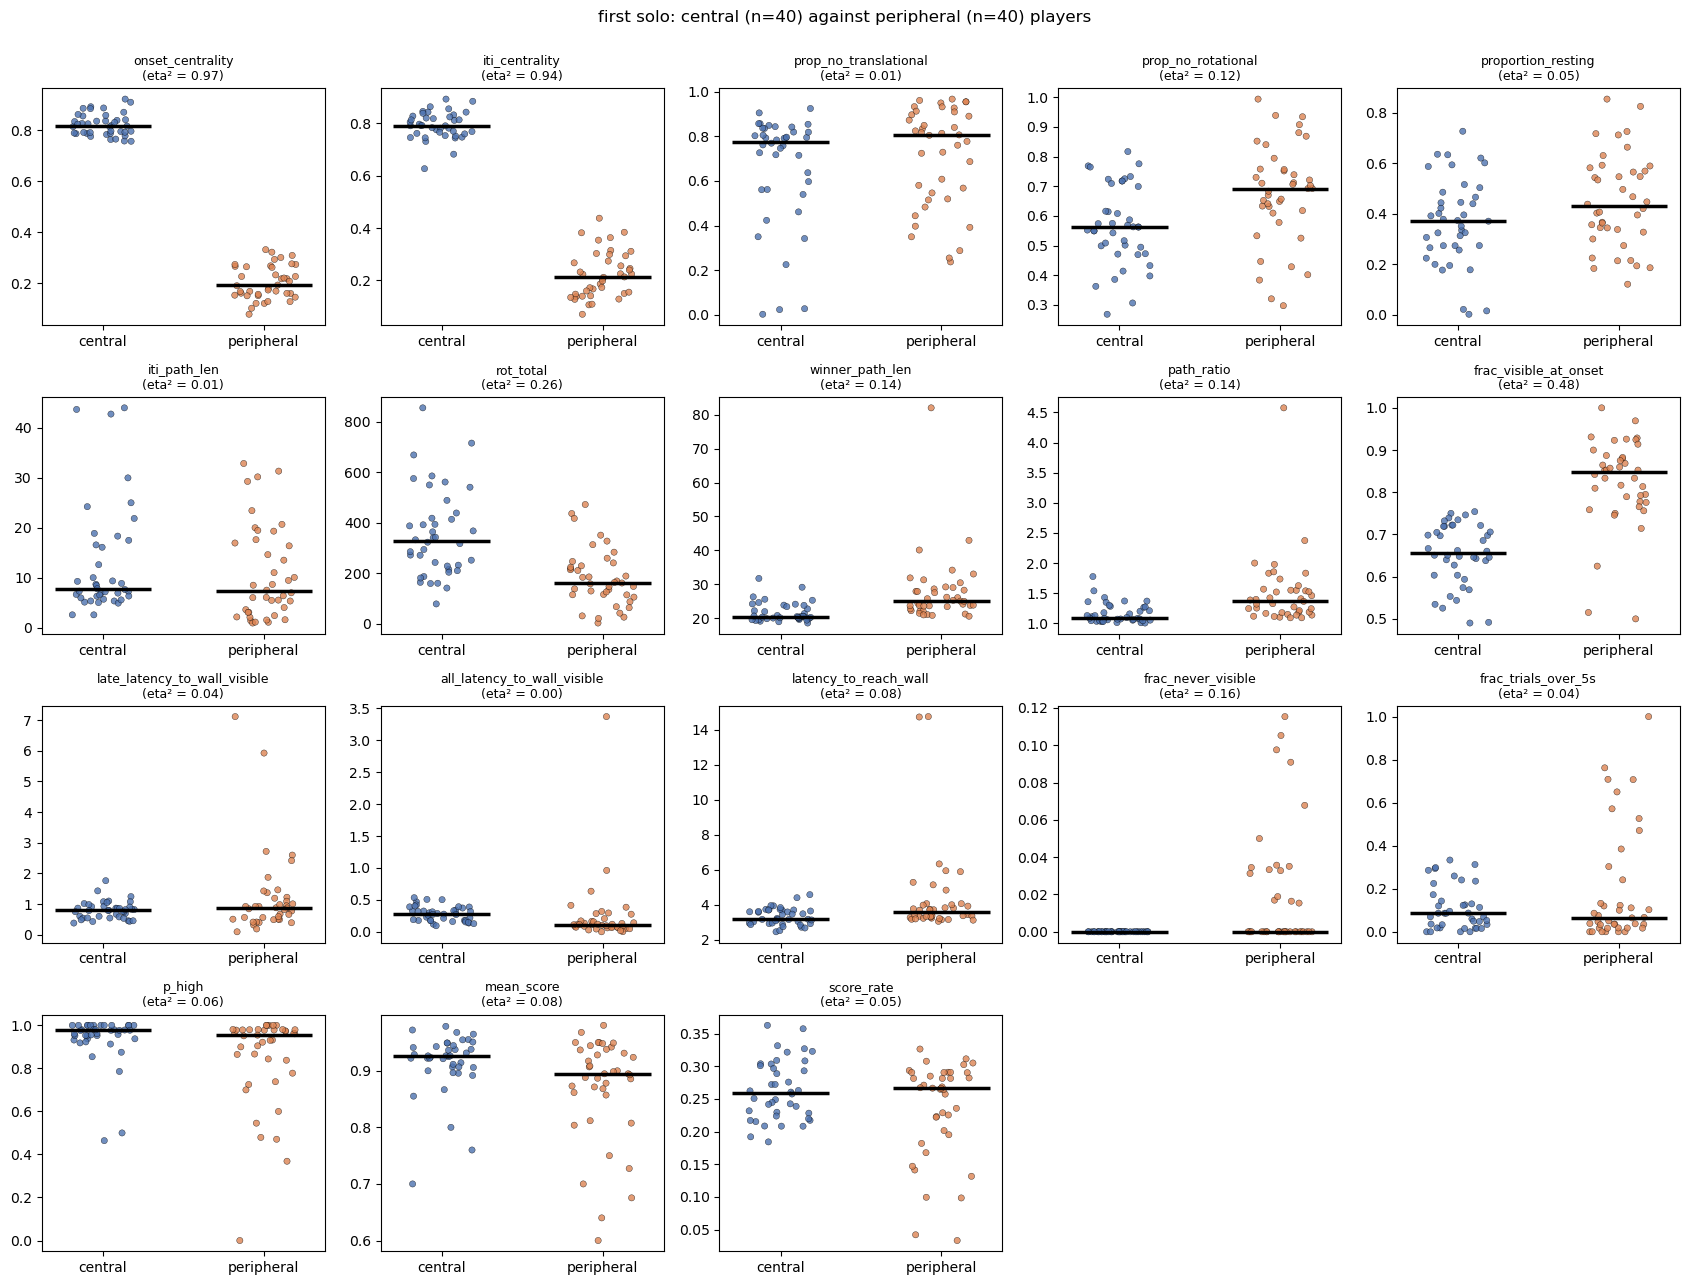

second solo: share of spread between the groups (eta²)


,metric,eta2_between_strategy,p_anova,central_mean,peripheral_mean
0,onset_centrality,0.986,0.000,0.833,0.127
1,iti_centrality,0.977,0.000,0.810,0.117
9,frac_visible_at_onset,0.699,0.000,0.672,0.854
13,frac_never_visible,0.317,0.000,0.000,0.033
4,proportion_resting,0.217,0.000,0.335,0.560
6,rot_total,0.210,0.000,413.744,187.949
2,prop_no_translational,0.126,0.001,0.636,0.827
5,iti_path_len,0.125,0.001,13.931,5.816
10,late_latency_to_wall_visible,0.117,0.002,0.722,1.330
3,prop_no_rotational,0.116,0.002,0.568,0.692


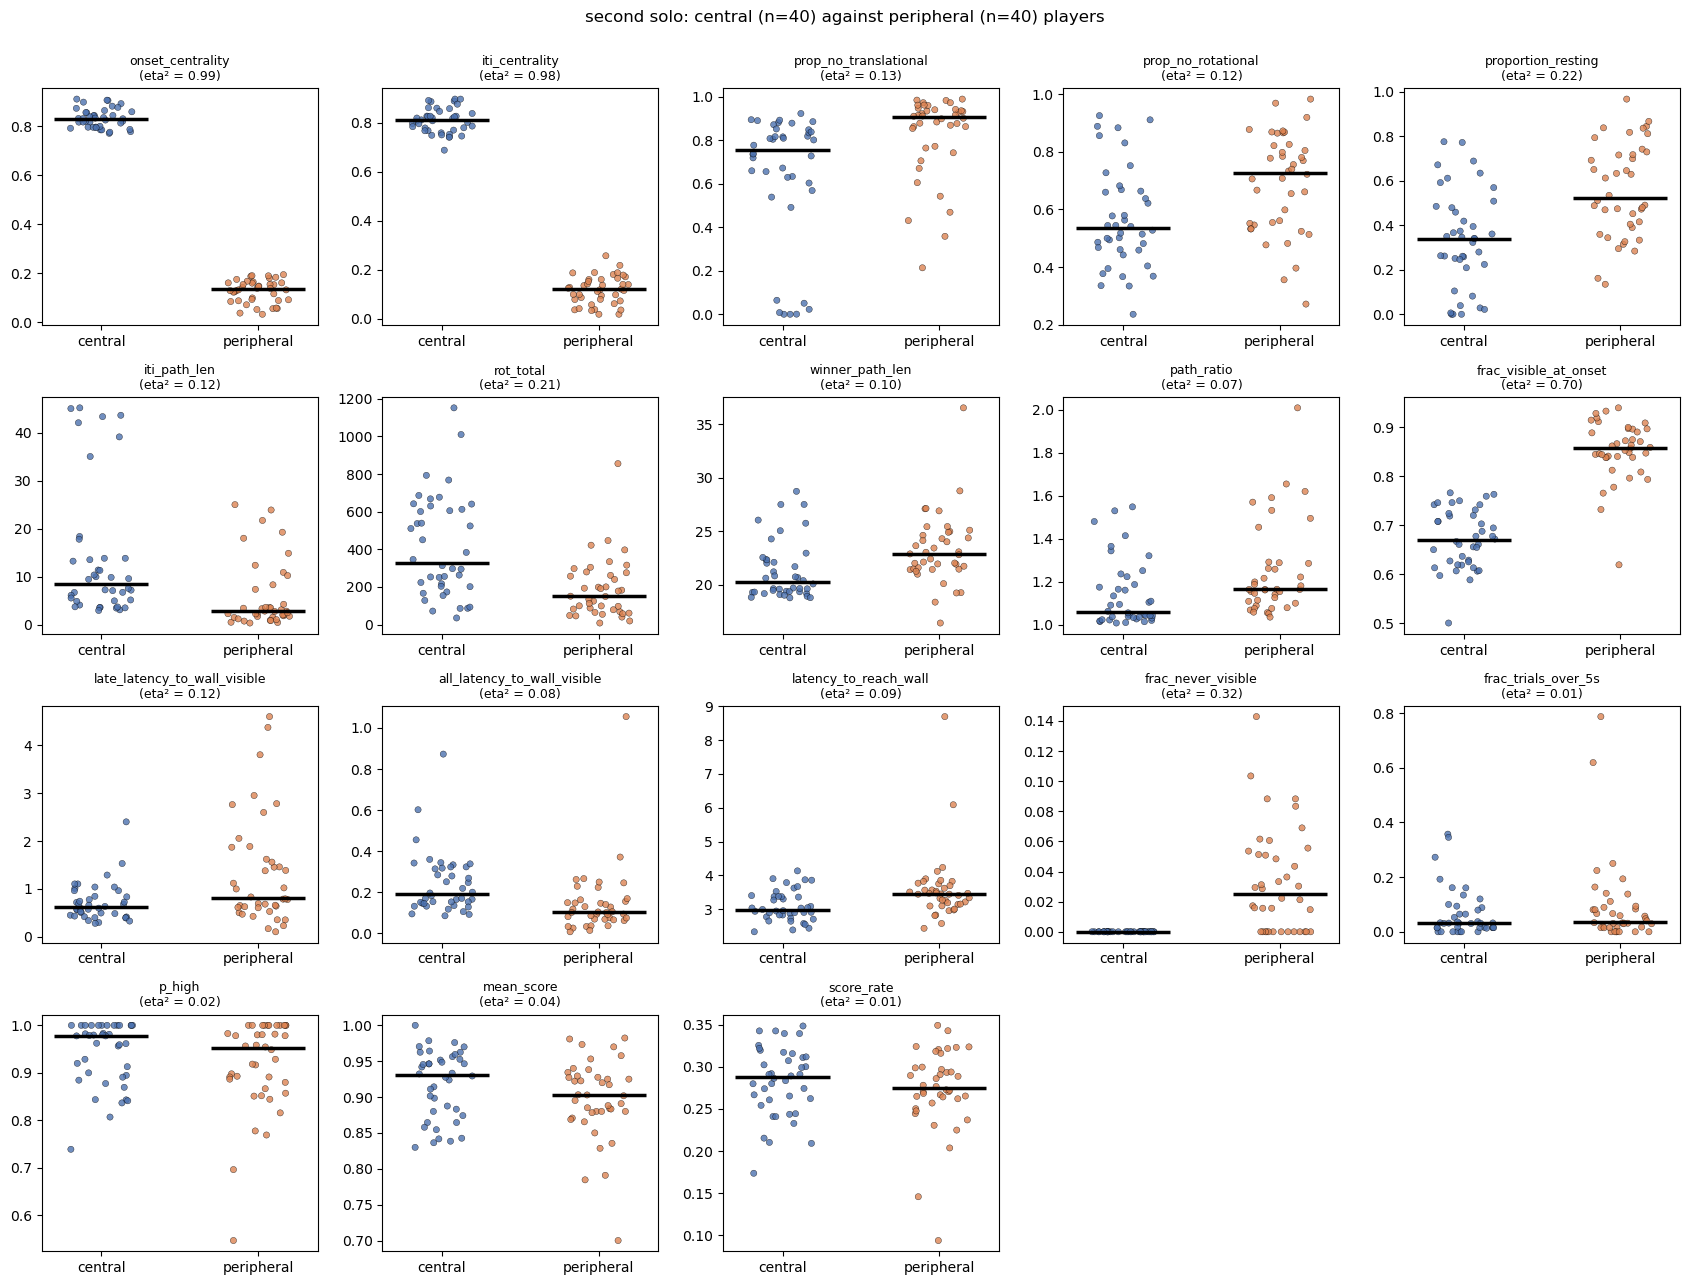

In [10]:
for st in hc.SOLO_TYPES:
    print(f'{LABELS[st]}: share of spread between the groups (eta²)')
    display(hc.group_variance(fingerprint, st).round(3))
    plot_fingerprint(st)

**Interpretation**

- The view, turning and resting differences from social appear in both solos.
- Route length reverses. In the solos, peripheral players take longer routes (27.7 against 21.7 in the first solo, 23.3 against 21.3 in the second). In social they take shorter ones. Social wins are a selected set of trials, and a peripheral player may win mostly when a trial wall is near them.
- First-solo peripheral players are slower (4.4 against 3.3 s) and reach High less often (0.85 against 0.94). Both gaps shrink in the second solo.
- Scores barely differ in either solo (eta² 0.08 or less).

## 5. The two groups across sessions

Group medians per session, one row per metric. Each session's groups are ranked from that session's players.

,first solo central,first solo peripheral,social central,social peripheral,second solo central,second solo peripheral
onset_centrality,0.817,0.191,0.828,0.163,0.832,0.135
iti_centrality,0.791,0.213,0.804,0.164,0.810,0.120
prop_no_translational,0.777,0.806,0.657,0.808,0.757,0.905
prop_no_rotational,0.563,0.692,0.485,0.643,0.534,0.727
proportion_resting,0.372,0.429,0.265,0.431,0.341,0.523
iti_path_len,7.737,7.264,12.214,6.332,8.509,2.770
rot_total,327.268,161.943,480.411,167.614,329.710,150.080
winner_path_len,20.464,24.988,19.408,15.092,20.239,22.853
path_ratio,1.085,1.377,1.077,1.291,1.059,1.164
frac_visible_at_onset,0.656,0.847,0.663,0.853,0.669,0.858


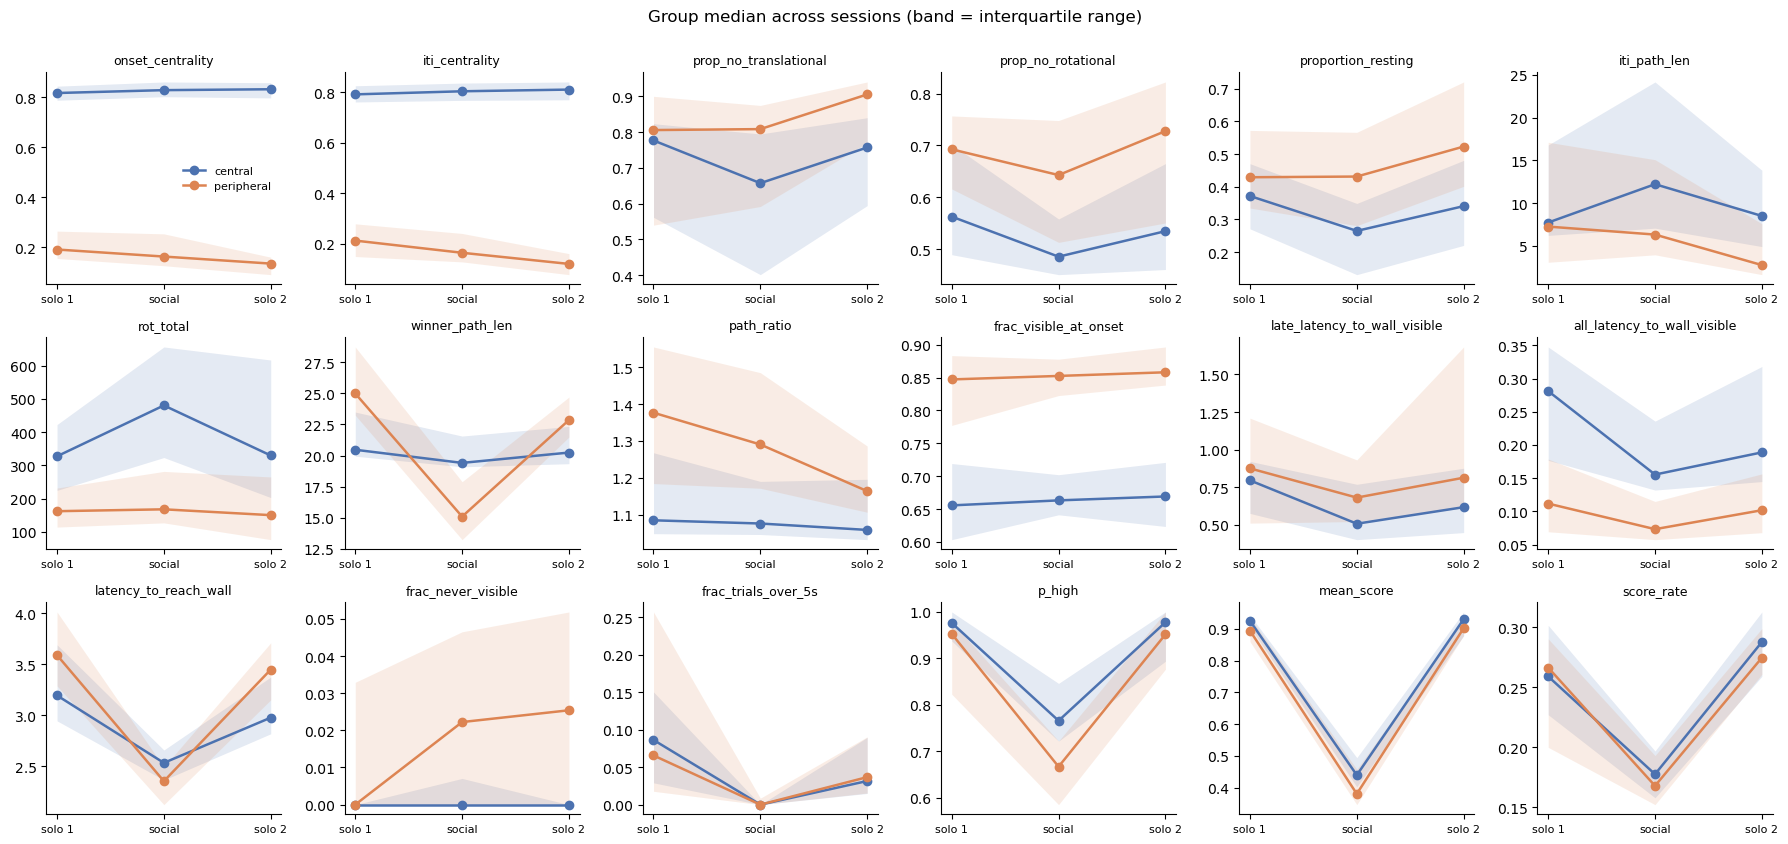

In [11]:
med = hc.group_medians(fingerprint)
med.columns = [f'{LABELS[st]} {g}' for st, g in med.columns]
display(med.round(3))

# plot each metric's group medians across the three sessions
metrics = [m for m in hc.FP_METRICS if m != 'win_rate']
ncol = 6
nrow = int(np.ceil(len(metrics) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 2.8 * nrow))
x = np.arange(len(hc.SESSION_TYPES))
sub = fingerprint[fingerprint['group'].isin(GROUPS)]
for ax, m in zip(axes.ravel(), metrics):
    for g in GROUPS:
        s = sub[sub['group'] == g].groupby('session_type')[m]
        q = s.quantile([0.25, 0.5, 0.75]).unstack().reindex(list(hc.SESSION_TYPES))
        ax.fill_between(x, q[0.25], q[0.75], color=PALETTE[g], alpha=0.15, lw=0)
        ax.plot(x, q[0.5], color=PALETTE[g], marker='o', lw=1.8, label=g)
    ax.set_xticks(x)
    ax.set_xticklabels(['solo 1', 'social', 'solo 2'], fontsize=8)
    ax.set_title(m, fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.ravel()[len(metrics):]:
    ax.axis('off')
axes.ravel()[0].legend(frameon=False, fontsize=8)
plt.suptitle('Group median across sessions (band = interquartile range)', y=1.0)
plt.tight_layout()
plt.show()

**Interpretation**

- Social differs from both solos for both groups. Players are faster (2.4 to 2.5 s against 3.0 to 3.6 s), reach High less often (0.67 to 0.77 against 0.95 to 0.98), and score less because they lose trials.
- Central players move more during the social ITI than in the solos (path 12.2 against 7.7 and 8.5, resting 0.27 against 0.37 and 0.34). Peripheral players do not.
- Second-solo peripheral players move least of all during the ITI (path 2.8, resting 0.52).

### Who is in each group

Players are grouped separately in each session. The tables show how the social groups were grouped in each solo.

In [12]:
groups_wide = hc.wide_table(players, 'group')
for st in hc.SOLO_TYPES:
    print(f'social group (rows) against {LABELS[st]} group (columns)')
    display(pd.crosstab(groups_wide['social'], groups_wide[st]).loc[GROUPS + ['middle'], GROUPS + ['middle']])

social group (rows) against first solo group (columns)


solo1,central,peripheral,middle
social,,,
central,17,1,22
peripheral,3,22,15
middle,20,17,83


social group (rows) against second solo group (columns)


solo2,central,peripheral,middle
social,,,
central,25,2,13
peripheral,1,28,11
middle,14,10,96


**Interpretation**

- Few players switch between the two ends. 1 to 3 social central or peripheral players are in the opposite solo group.
- Of the 40 social central players, 17 are central in the first solo and 25 in the second. Of the 40 social peripheral players, 22 and 28 are.
- The rest sit in the middle 60% of that solo, so the solo and social groups are largely different people. This is partly because each group is a fixed 40 players.

## Notes

- **Groups are provisional.** The 20% cuts take a fixed number of players, whatever the shape of the distribution. `EXTREME_FRAC` changes them, and the cached tables do not need rebuilding.
- **Partners are not independent.** Both players of an experiment can fall in one social group, and their social metrics depend on each other (`win_rate`, and which trials count as wins).
- **Own-win metrics use fewer trials** for players who rarely win. `n_wins` and `n_high_low_wins` in the fingerprint table give the counts.
- **Protocol differences.** 2024 solos are about half as long and some 2024 experiments used a different wall separation mix (see `strategy_characterisation.ipynb`, section 1).
- **Movement thresholds come from the agents.** They have not been checked against human input noise.